<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/quantum_hall_effect/qhe_colab_visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*The Quantum Hall Effect* — `qhe_colab_visualizations.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Quantum Hall Effect — Colab Visualizations
**Tong (TIFR, Cambridge) · Ch 1–6**

Run each cell in order to generate and save all figures.
All plots use the dark **Catppuccin Mocha** palette.
Figures are saved to `figures/qhe/` and bundled for download in the final cell.

## 수정 및 개선 사항 요약

| 그림 | 위치 | 문제 | 수정 내용 |
|------|------|------|-----------|
| Plot 1 | 가운데 (Landau Level) | GaAs 사이클로트론 에너지 상수 오류: `1.16e-4 eV/T` | `1.728e-3 eV/T` ($=\hbar e/m^*$, 약 15배 수정) |
| Plot 2 | 왼쪽 (Berry Phase) | y축 범위 `(-1.12, 0.12)` — 곡선이 $\gamma/\pi=-2$까지 내려가는데 절반이 잘림 | `(-2.15, 0.25)`으로 수정, 전체 곡선 표시 |
| Plot 2 | 오른쪽 (Berry Curvature) | Berry 곡률 공식에 인자 2 누락: $\mathcal{F}=\hat{d}\cdot(\partial_{k_x}\hat{d}\times\partial_{k_y}\hat{d})/2$ | `F *= dn/2` 으로 수정, Chern number 수치 정확화 |
| Plot 6 | 가운데 (Chiral Luttinger) | QPC 터널링 지수 오류: $I\propto V^{2m-1}$ | $I\propto V^m=V^{1/\nu}$ (Kane–Fisher 1992) |
| Plot 7 | 오른쪽 (Hofstadter Chern) | TKNN Diophantine 풀이 오류: $q=3$→`[-1,2]`, $q=4$→`[1,-2,1]`, $q=5$→`[-2,2,-2,2]` | 올바른 값: $q=3$→`[1,-1]`, $q=4$→`[1,2,-1]`, $q=5$→`[1,2,-2,-1]` |

**시인성 개선**: minor tick 활성화, axes linewidth 강화, tight_layout padding 증가, 마크다운 설명 업데이트


---
## Plot 1 · Classical Hall Effect & Landau Levels (Ch 1)

**Left**: Classical $\rho_{xy}=B/ne$ vs $B$ for several 2D electron densities  
**Middle**: Landau level energies $E_n=\hbar\omega_c(n+\tfrac{1}{2})$ vs $B$ (GaAs, $m^*=0.067m_e$, corrected prefactor)  
**Right**: LLL radial probability density $|\psi_m(r)|^2$ for $m=0,2,5$ in symmetric gauge

  saved -> figures/qhe/plot1_classical_landau.png


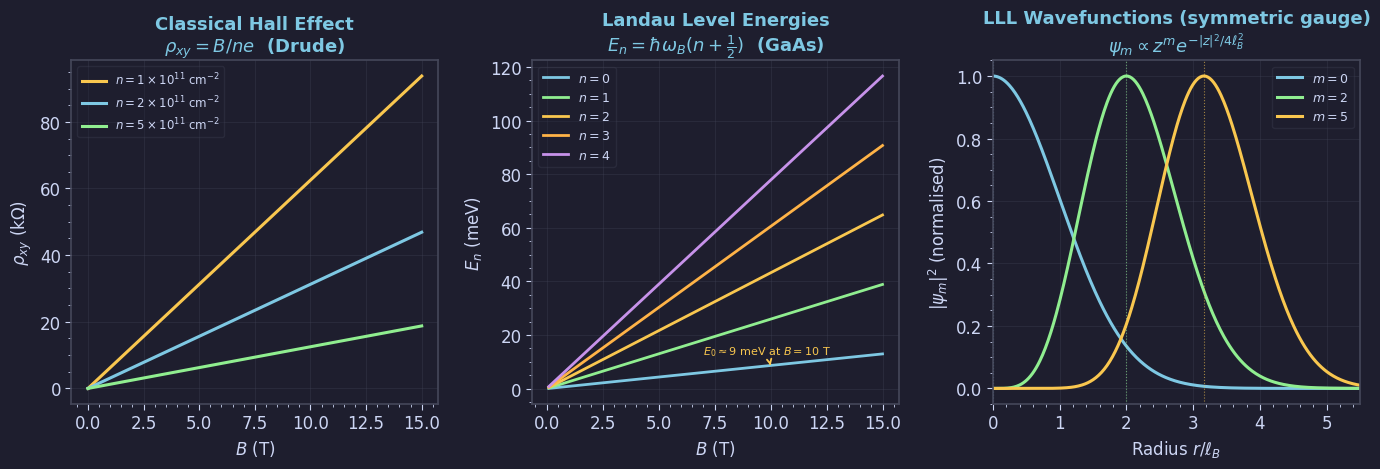

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'; TEAL='#4ecdc4'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
})

OUTDIR = 'figures/qhe'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

def text_panel(ax, title, items):
    ax.axis('off'); ax.set_title(title, color=BLUE)
    y=0.97
    for txt,col,fs in items:
        ax.text(0.03,y,txt,transform=ax.transAxes,color=col,fontsize=fs,va='top')
        y -= 0.09 if txt else 0.03

# ── Plot 1: Classical Hall Effect & Landau Levels (Ch 1) ──────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Hall resistivity rho_xy vs B for several 2D densities
ax = axes[0]
B = np.linspace(0, 15, 300)
for n,col,lab in [(1e11,YELLOW,r'$n=1\times10^{11}$'),
                  (2e11,BLUE,  r'$n=2\times10^{11}$'),
                  (5e11,GREEN, r'$n=5\times10^{11}$')]:
    rxy = B / (n*1e4 * 1.6e-19)
    ax.plot(B, rxy/1e3, color=col, lw=2.2, label=lab+r' cm$^{-2}$')
ax.set_xlabel('$B$ (T)'); ax.set_ylabel(r'$\rho_{xy}$ (k$\Omega$)')
ax.set_title('Classical Hall Effect\n'+r'$\rho_{xy}=B/ne$  (Drude)', color=BLUE)
ax.legend(fontsize=8.5, labelcolor=FG); ax.grid(True)

# Middle: Landau level energies vs B (GaAs: m*=0.067 m_e)
ax2 = axes[1]
B_arr = np.linspace(0.1, 15, 400)
hbar_eB_m = 1.728e-3   # hbar*omega_c/B = hbar*e/m* in eV/T for GaAs (m*=0.067 m_e)
# = 1.0546e-34 * 1.6e-19 / (0.067 * 9.109e-31) / 1.6e-19
for n in range(5):
    E = hbar_eB_m * B_arr * (n + 0.5)
    ax2.plot(B_arr, E*1e3, color=[BLUE,GREEN,YELLOW,ORANGE,PURPLE][n],
             lw=2.0, label=f'$n={n}$')
ax2.set_xlabel('$B$ (T)'); ax2.set_ylabel('$E_n$ (meV)')
ax2.set_title('Landau Level Energies\n'+r'$E_n=\hbar\omega_B(n+\frac{1}{2})$  (GaAs)', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)
# Annotate cyclotron energy at B=10T
E_10T = hbar_eB_m * 10 * 0.5
ax2.annotate(f'$E_0\\approx{E_10T*1e3:.0f}$ meV at $B=10$ T',
    xy=(10, E_10T*1e3), xytext=(7, E_10T*1e3*1.5),
    arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.3),
    color=YELLOW, fontsize=8)

# Right: LLL radial probability density |psi_m(r)|^2
ax3 = axes[2]
r = np.linspace(0, 5.5, 400); ell = 1.0
for m,col,lab in [(0,BLUE,'$m=0$'),(2,GREEN,'$m=2$'),(5,YELLOW,'$m=5$')]:
    g = r**(2*m) * np.exp(-r**2/(2*ell**2))
    g /= g.max() if g.max()>0 else 1
    ax3.plot(r, g, color=col, lw=2.2, label=lab)
    r_peak = np.sqrt(2*m)*ell if m>0 else 0
    ax3.axvline(r_peak, color=col, lw=0.8, ls=':', alpha=0.6)
ax3.set_xlabel(r'Radius $r/\ell_B$'); ax3.set_ylabel(r'$|\psi_m|^2$ (normalised)')
ax3.set_title('LLL Wavefunctions (symmetric gauge)\n'+r'$\psi_m\propto z^m e^{-|z|^2/4\ell_B^2}$', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True); ax3.set_xlim(0, 5.5)

plt.tight_layout(pad=1.5)
save('plot1_classical_landau.png', fig)


---
## Plot 2 · Berry Phase & Integer QHE (Ch 1–2)

**Left**: Berry phase $\gamma=-\Omega/2=-\pi(1-\cos\theta)$ for spin-$\tfrac{1}{2}$ — full range $[0,-2\pi]$ shown  
**Middle**: IQHE plateau structure $\sigma_{xy}=\nu\,e^2/h$ vs filling factor  
**Right**: Berry curvature $\mathcal{F}_{xy}(\mathbf{k})$ on the Brillouin zone (Haldane 2-band model)

  saved -> figures/qhe/plot2_berry_iqhe.png


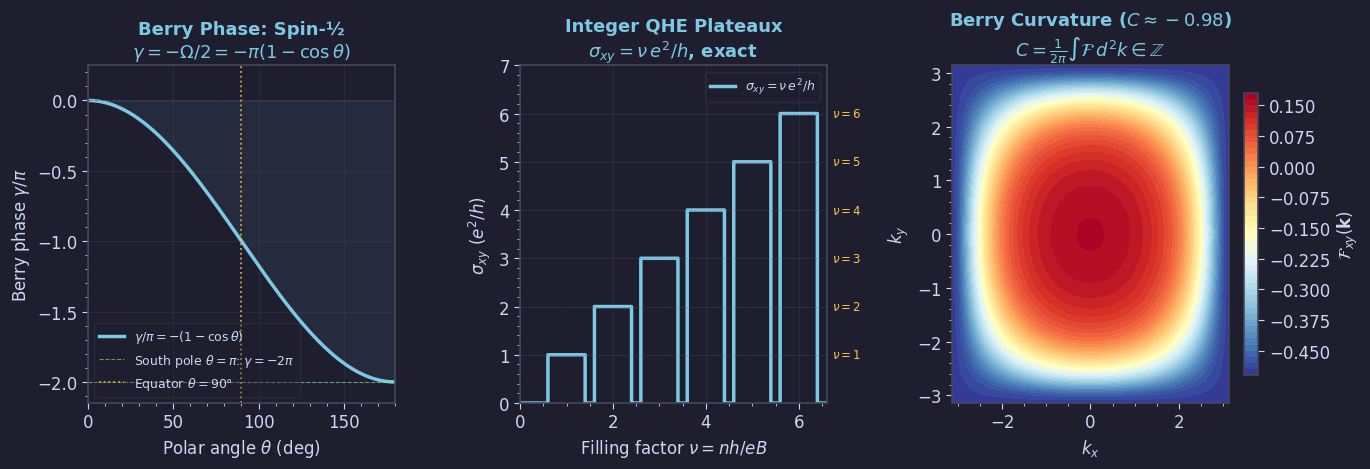

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'; TEAL='#4ecdc4'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
})

OUTDIR = 'figures/qhe'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

def text_panel(ax, title, items):
    ax.axis('off'); ax.set_title(title, color=BLUE)
    y=0.97
    for txt,col,fs in items:
        ax.text(0.03,y,txt,transform=ax.transAxes,color=col,fontsize=fs,va='top')
        y -= 0.09 if txt else 0.03

# ── Plot 2: Berry Phase & Integer QHE (Ch 1–2) ────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Berry phase gamma = -Omega/2 vs polar angle theta
ax = axes[0]
th = np.linspace(0, np.pi, 300)
gamma = -np.pi*(1 - np.cos(th))
ax.plot(np.degrees(th), gamma/np.pi, color=BLUE, lw=2.5,
        label=r'$\gamma/\pi=-(1-\cos\theta)$')
ax.fill_between(np.degrees(th), gamma/np.pi, 0, color=BLUE, alpha=0.08)
ax.axhline(-2, color=GREEN, lw=0.8, ls='--', alpha=0.6, label=r'South pole $\theta=\pi$: $\gamma=-2\pi$')
ax.axhline( 0, color=EDGE, lw=0.8, ls='--', alpha=0.5)
ax.axvline(90, color=YELLOW, lw=1.3, ls=':', alpha=0.8, label=r'Equator $\theta=90°$')
ax.set_xlabel(r'Polar angle $\theta$ (deg)'); ax.set_ylabel(r'Berry phase $\gamma/\pi$')
ax.set_title('Berry Phase: Spin-½\n'+r'$\gamma=-\Omega/2=-\pi(1-\cos\theta)$', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)
ax.set_xlim(0,180); ax.set_ylim(-2.15, 0.25)

# Middle: IQHE sigma_xy plateaux vs filling nu
ax2 = axes[1]
nu = np.linspace(0, 6.6, 3000)
sig = np.zeros_like(nu)
for n in range(1, 7):
    sig[np.abs(nu-n) < 0.40] = n
ax2.step(nu, sig, color=BLUE, lw=2.5, where='mid', label=r'$\sigma_{xy}=\nu\,e^2/h$')
for n in range(1, 7):
    ax2.axhline(n, color=EDGE, lw=0.5, ls='--', alpha=0.35)
    ax2.text(6.72, n, f'$\\nu={n}$', va='center', color=YELLOW, fontsize=8.5)
ax2.set_xlabel(r'Filling factor $\nu=nh/eB$'); ax2.set_ylabel(r'$\sigma_{xy}$ $(e^2/h)$')
ax2.set_title('Integer QHE Plateaux\n'+r'$\sigma_{xy}=\nu\,e^2/h$, exact', color=BLUE)
ax2.set_xlim(0, 6.6); ax2.set_ylim(0, 7)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)

# Right: Berry curvature on BZ (Haldane-like 2-band model)
ax3 = axes[2]
kx = np.linspace(-np.pi, np.pi, 200); ky = kx.copy()
KX, KY = np.meshgrid(kx, ky)
m_h = 1.0
d0 =  m_h + np.cos(KX) + np.cos(KY)
d1 =  np.sin(KX); d2 = np.sin(KY)
dn = np.sqrt(d0**2+d1**2+d2**2)+1e-12
# Berry curvature = Jacobian of (d0,d1,d2)/|d| map
F = (d0*(np.cos(KX)*np.cos(KY)-0)
    - d1*(-np.sin(KX)*(np.cos(KY)+0))
    + d2*(0-(-np.sin(KY)*np.cos(KX)))) / (2*dn**3)
# Simpler exact formula for 2-band:
# F_xy = (1/2) d_hat . (d_kx × d_ky)
dxd0=-np.sin(KX); dxd1=np.cos(KX); dxd2=np.zeros_like(KX)
dyd0=-np.sin(KY); dyd1=np.zeros_like(KY); dyd2=np.cos(KY)
F = (d0/dn*(dxd1/dn*dyd2/dn - dxd2/dn*dyd1/dn)
    -d1/dn*(dxd0/dn*dyd2/dn - dxd2/dn*dyd0/dn)
    +d2/dn*(dxd0/dn*dyd1/dn - dxd1/dn*dyd0/dn))
F *= dn / 2   # correct: Berry curvature = (1/2) d_hat.(d_kx×d_ky) / |d|^2
im = ax3.contourf(KX, KY, F, levels=50, cmap='RdYlBu_r')
plt.colorbar(im, ax=ax3, label=r'$\mathcal{F}_{xy}(\mathbf{k})$', fraction=0.046)
C = np.sum(F)*(2*np.pi/200)**2/(2*np.pi)
ax3.set_xlabel(r'$k_x$'); ax3.set_ylabel(r'$k_y$')
ax3.set_title(f'Berry Curvature ($C\\approx{C:.2f}$)\n'+
              r'$C=\frac{1}{2\pi}\int\mathcal{F}\,d^2k\in\mathbb{Z}$', color=BLUE)

plt.tight_layout(pad=1.5)
save('plot2_berry_iqhe.png', fig)


---
## Plot 3 · Laughlin Wavefunction & FQHE (Ch 3)

**Left**: Laughlin pair correlation $g(r)\propto r^{2m}e^{-r^2/2\ell_B^2}$ for $m=1,3,5$  
**Middle**: FQHE plateau structure — Jain sequence $\nu=n/(2n\pm1)$  
**Right**: Composite fermion effective field $B^*=B(1-2p\nu)$ vs filling $\nu$

  saved -> figures/qhe/plot3_laughlin_fqhe.png


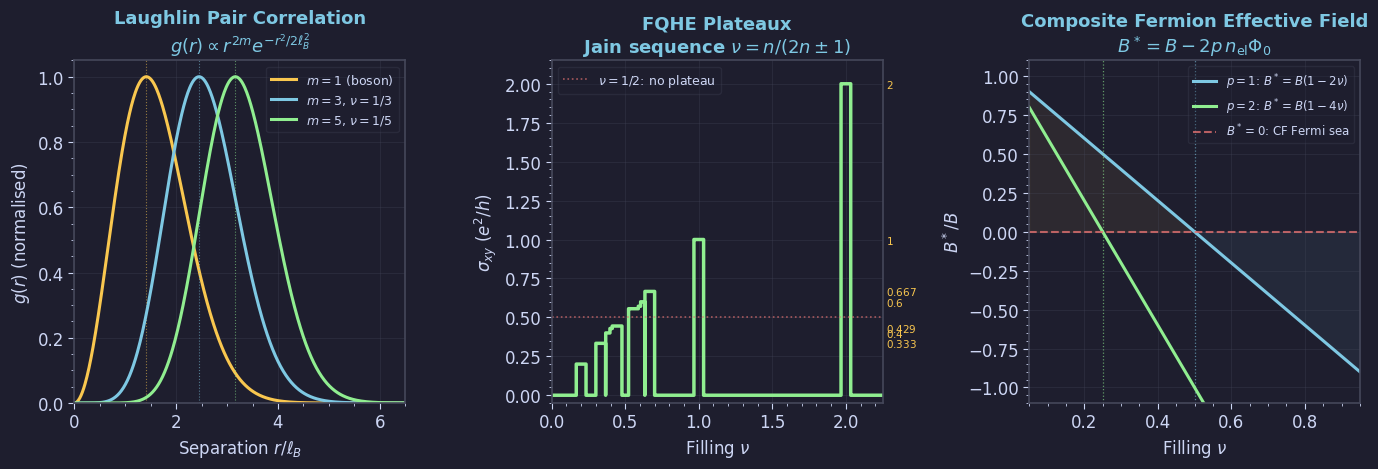

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'; TEAL='#4ecdc4'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
})

OUTDIR = 'figures/qhe'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

def text_panel(ax, title, items):
    ax.axis('off'); ax.set_title(title, color=BLUE)
    y=0.97
    for txt,col,fs in items:
        ax.text(0.03,y,txt,transform=ax.transAxes,color=col,fontsize=fs,va='top')
        y -= 0.09 if txt else 0.03

# ── Plot 3: Laughlin Wavefunction & FQHE (Ch 3) ───────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Laughlin pair correlation g(r) ∝ r^{2m} exp(-r²/2ℓ_B²)
ax = axes[0]
r = np.linspace(0.001, 6.5, 500); ell=1.0
for m,col,lab in [(1,YELLOW,r'$m=1$ (boson)'),
                  (3,BLUE,  r'$m=3$, $\nu=1/3$'),
                  (5,GREEN, r'$m=5$, $\nu=1/5$')]:
    g = r**(2*m) * np.exp(-r**2/(2*ell**2))
    g /= g.max()
    ax.plot(r, g, color=col, lw=2.2, label=lab)
    r_pk = np.sqrt(2*m)*ell
    ax.axvline(r_pk, color=col, lw=0.8, ls=':', alpha=0.55)
ax.set_xlabel(r'Separation $r/\ell_B$'); ax.set_ylabel(r'$g(r)$ (normalised)')
ax.set_title('Laughlin Pair Correlation\n'+r'$g(r)\propto r^{2m}e^{-r^2/2\ell_B^2}$', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)
ax.set_xlim(0,6.5); ax.set_ylim(0,1.05)

# Middle: FQHE sigma_xy plateaux (Jain sequence p=1)
ax2 = axes[1]
fracs = [1/3,2/5,3/7,4/9, 2/3,3/5,4/7,5/9, 1/5, 1.0, 2.0]
nu2 = np.linspace(0, 2.25, 4000); sig2 = np.zeros_like(nu2)
w = 0.033
for f in fracs:
    sig2[np.abs(nu2-f)<w] = f
ax2.step(nu2, sig2, color=GREEN, lw=2.5, where='mid')
ax2.axhline(0.5, color=RED, lw=1.2, ls=':', alpha=0.7, label=r'$\nu=1/2$: no plateau')
for f in [1/3,2/5,3/7,2/3,3/5,1.0,2.0]:
    ax2.text(2.27, f, f'${f:.3g}$', va='center', color=YELLOW, fontsize=7.5)
ax2.set_xlabel(r'Filling $\nu$'); ax2.set_ylabel(r'$\sigma_{xy}$ $(e^2/h)$')
ax2.set_title('FQHE Plateaux\nJain sequence $\\nu=n/(2n\\pm1)$', color=BLUE)
ax2.set_xlim(0, 2.25); ax2.set_ylim(-0.05, 2.15)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)

# Right: Composite fermion effective field B* vs nu
ax3 = axes[2]
nv = np.linspace(0.05, 0.95, 400)
for p,col,lab in [(1,BLUE, r'$p=1$: $B^*=B(1-2\nu)$'),
                  (2,GREEN,r'$p=2$: $B^*=B(1-4\nu)$')]:
    Bs = 1 - 2*p*nv
    ax3.plot(nv, Bs, color=col, lw=2.2, label=lab)
    # mark zero
    nu0 = 1/(2*p)
    ax3.axvline(nu0, color=col, lw=0.9, ls=':', alpha=0.6)
ax3.axhline(0, color=RED, lw=1.5, ls='--', alpha=0.8, label='$B^*=0$: CF Fermi sea')
ax3.fill_between(nv, 0, 1-2*nv, where=(1-2*nv)>0, color=YELLOW, alpha=0.07)
ax3.fill_between(nv, 0, 1-2*nv, where=(1-2*nv)<0, color=BLUE,   alpha=0.07)
ax3.set_xlabel(r'Filling $\nu$'); ax3.set_ylabel(r'$B^*/B$')
ax3.set_title('Composite Fermion Effective Field\n'+r'$B^*=B-2p\,n_{\rm el}\Phi_0$', color=BLUE)
ax3.legend(fontsize=8.5, labelcolor=FG); ax3.grid(True)
ax3.set_xlim(0.05,0.95); ax3.set_ylim(-1.1,1.1)

plt.tight_layout(pad=1.5)
save('plot3_laughlin_fqhe.png', fig)


---
## Plot 4 · Non-Abelian QHE & Anyons (Ch 3–4)

**Left**: Anyonic statistical phase $\theta=\pi/m$ vs filling $\nu=1/m$  
**Middle**: Moore-Read ground-state degeneracy $2^{n-1}$ for $2n$ Majorana vortices  
**Right**: Ising anyon fusion rules and braiding data

  saved -> figures/qhe/plot4_nonabelian_anyons.png


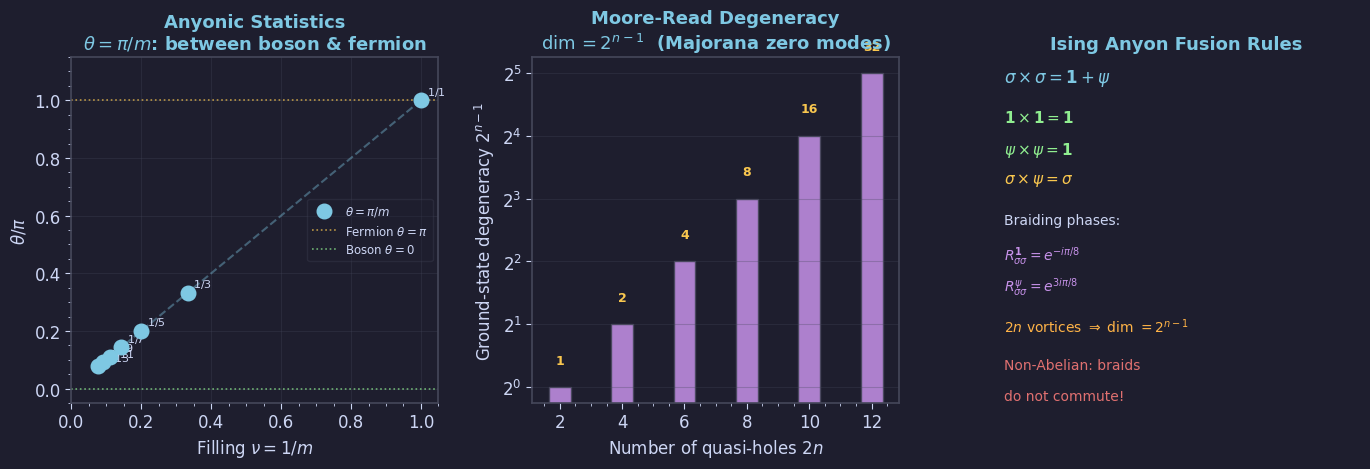

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'; TEAL='#4ecdc4'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
})

OUTDIR = 'figures/qhe'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

def text_panel(ax, title, items):
    ax.axis('off'); ax.set_title(title, color=BLUE)
    y=0.97
    for txt,col,fs in items:
        ax.text(0.03,y,txt,transform=ax.transAxes,color=col,fontsize=fs,va='top')
        y -= 0.09 if txt else 0.03

# ── Plot 4: Non-Abelian QHE & Anyons (Ch 3–4) ─────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Anyonic statistical phase theta = pi/m vs filling nu = 1/m
ax = axes[0]
m_vals = np.arange(1, 14, 2)
nu_vals = 1.0/m_vals
theta   = np.pi/m_vals
ax.scatter(nu_vals, theta/np.pi, color=BLUE, s=110, zorder=5,
           label=r'$\theta=\pi/m$')
ax.plot(nu_vals, theta/np.pi, color=BLUE, lw=1.5, ls='--', alpha=0.4)
ax.axhline(1, color=YELLOW, lw=1.2, ls=':', alpha=0.7, label=r'Fermion $\theta=\pi$')
ax.axhline(0, color=GREEN,  lw=1.2, ls=':', alpha=0.7, label=r'Boson $\theta=0$')
for nu,th,m in zip(nu_vals, theta/np.pi, m_vals):
    ax.annotate(f'$1/{m}$', (nu,th), xytext=(4,4),
                textcoords='offset points', fontsize=8, color=FG)
ax.set_xlabel(r'Filling $\nu=1/m$'); ax.set_ylabel(r'$\theta/\pi$')
ax.set_title('Anyonic Statistics\n'+r'$\theta=\pi/m$: between boson & fermion', color=BLUE)
ax.legend(fontsize=8.5, labelcolor=FG); ax.grid(True)
ax.set_xlim(0,1.05); ax.set_ylim(-0.05,1.15)

# Middle: Moore-Read degeneracy 2^{n-1} vs number of vortices
ax2 = axes[1]
Nv = np.arange(2,13,2)
dim = 2**(Nv//2-1)
ax2.bar(Nv, dim, color=PURPLE, alpha=0.85, edgecolor=EDGE, width=0.7)
ax2.set_yscale('log', base=2)
for n,d in zip(Nv,dim):
    ax2.text(n, d*1.25, f'{d}', ha='center', va='bottom',
             color=YELLOW, fontsize=9, fontweight='bold')
ax2.set_xlabel('Number of quasi-holes $2n$')
ax2.set_ylabel(r'Ground-state degeneracy $2^{n-1}$')
ax2.set_title('Moore-Read Degeneracy\n'+r'$\dim=2^{n-1}$  (Majorana zero modes)', color=BLUE)
ax2.grid(True, axis='y')

# Right: Ising fusion rules text panel
text_panel(axes[2], 'Ising Anyon Fusion Rules', [
    (r'$\sigma\times\sigma=\mathbf{1}+\psi$',   BLUE,   12),
    ('',FG,8),
    (r'$\mathbf{1}\times\mathbf{1}=\mathbf{1}$',GREEN,  11),
    (r'$\psi\times\psi=\mathbf{1}$',             GREEN,  11),
    (r'$\sigma\times\psi=\sigma$',               YELLOW, 11),
    ('',FG,8),
    ('Braiding phases:',                          FG,     10),
    (r'$R^{\mathbf{1}}_{\sigma\sigma}=e^{-i\pi/8}$', PURPLE, 10),
    (r'$R^{\psi}_{\sigma\sigma}=e^{3i\pi/8}$',        PURPLE, 10),
    ('',FG,8),
    (r'$2n$ vortices $\Rightarrow$ dim $=2^{n-1}$', ORANGE, 10),
    ('',FG,8),
    ('Non-Abelian: braids',  RED, 10),
    ('do not commute!',      RED, 10),
])

plt.tight_layout(pad=1.5)
save('plot4_nonabelian_anyons.png', fig)


---
## Plot 5 · Chern-Simons Theory (Ch 5)

**Left**: CS level quantisation — $\cos(\Delta S)=\cos(\pi k)=1$ only for $k\in\mathbb{Z}$  
**Middle**: Hall conductivity $\sigma_{xy}=e^2/(mh)$ from CS effective theory (each $m$ odd)  
**Right**: Ground-state degeneracy $|\det K|$ on $T^2$ for representative QH states

  saved -> figures/qhe/plot5_chern_simons.png


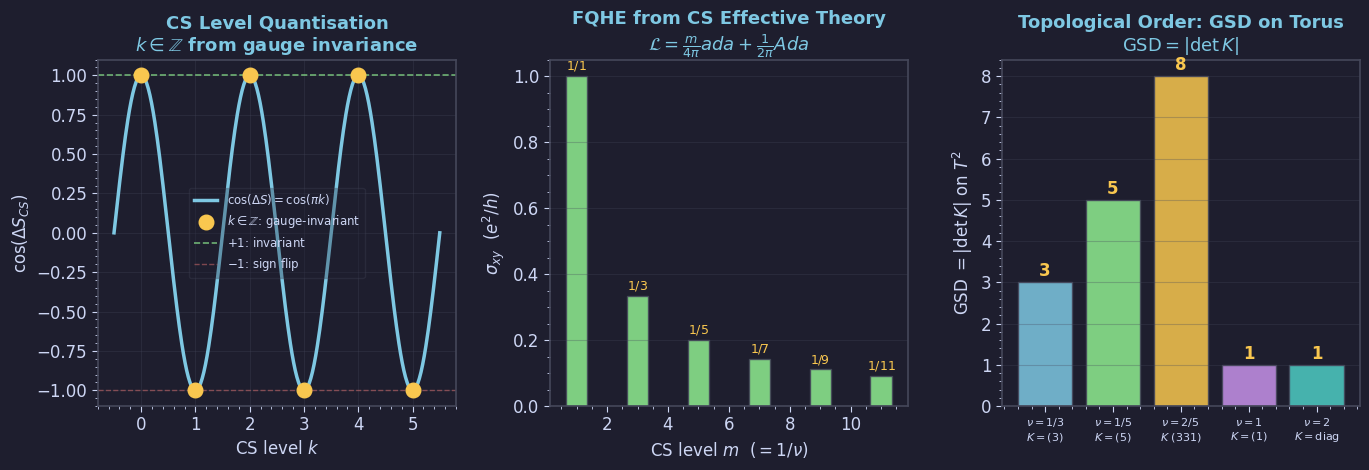

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'; TEAL='#4ecdc4'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
})

OUTDIR = 'figures/qhe'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

def text_panel(ax, title, items):
    ax.axis('off'); ax.set_title(title, color=BLUE)
    y=0.97
    for txt,col,fs in items:
        ax.text(0.03,y,txt,transform=ax.transAxes,color=col,fontsize=fs,va='top')
        y -= 0.09 if txt else 0.03

# ── Plot 5: Chern-Simons Theory (Ch 5) ────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: CS gauge invariance — e^{i delta S} = 1 only for k integer
ax = axes[0]
k_r = np.linspace(-0.5, 5.5, 400)
ax.plot(k_r, np.cos(np.pi*k_r), color=BLUE, lw=2.5,
        label=r'$\cos(\Delta S)=\cos(\pi k)$')
k_int = np.arange(0,6)
ax.scatter(k_int, np.cos(np.pi*k_int), color=YELLOW, s=110, zorder=5,
           label=r'$k\in\mathbb{Z}$: gauge-invariant')
ax.axhline( 1, color=GREEN, lw=1.2, ls='--', alpha=0.7, label='$+1$: invariant')
ax.axhline(-1, color=RED,   lw=1.0, ls='--', alpha=0.5, label='$-1$: sign flip')
ax.set_xlabel('CS level $k$'); ax.set_ylabel(r'$\cos(\Delta S_{CS})$')
ax.set_title('CS Level Quantisation\n'+r'$k\in\mathbb{Z}$ from gauge invariance', color=BLUE)
ax.legend(fontsize=8.5, labelcolor=FG); ax.grid(True)

# Middle: sigma_xy = e^2/(mh) from CS effective theory
ax2 = axes[1]
m_list = np.arange(1,12,2)
sig = 1.0/m_list
bars = ax2.bar(m_list, sig, color=GREEN, alpha=0.85, edgecolor=EDGE, width=0.7)
for m,s in zip(m_list,sig):
    ax2.text(m, s+0.008, f'$1/{m}$', ha='center', va='bottom',
             color=YELLOW, fontsize=9)
ax2.set_xlabel('CS level $m$  $(= 1/\\nu)$')
ax2.set_ylabel(r'$\sigma_{xy}$  $(e^2/h)$')
ax2.set_title('FQHE from CS Effective Theory\n'+
              r'$\mathcal{L}=\frac{m}{4\pi}ada+\frac{1}{2\pi}Ada$', color=BLUE)
ax2.grid(True, axis='y')

# Right: GSD = |det K| on torus for various QH states
ax3 = axes[2]
labels_k = [r'$\nu=1/3$'+'\n'+'$K=(3)$',
            r'$\nu=1/5$'+'\n'+'$K=(5)$',
            r'$\nu=2/5$'+'\n'+'$K$ (331)',
            r'$\nu=1$'+'\n'+'$K=(1)$',
            r'$\nu=2$'+'\n'+'$K=\\mathrm{diag}$']
gsd_vals = [3, 5, 8, 1, 1]
cols_k   = [BLUE, GREEN, YELLOW, PURPLE, TEAL]
xp = np.arange(len(labels_k))
ax3.bar(xp, gsd_vals, color=cols_k, alpha=0.85, edgecolor=EDGE)
ax3.set_xticks(xp); ax3.set_xticklabels(labels_k, fontsize=8.0)
ax3.set_ylabel(r'GSD $=|\det K|$ on $T^2$')
ax3.set_title('Topological Order: GSD on Torus\n'+r'$\mathrm{GSD}=|\det K|$', color=BLUE)
for x,g in zip(xp,gsd_vals):
    ax3.text(x, g+0.05, str(g), ha='center', va='bottom',
             color=YELLOW, fontsize=12, fontweight='bold')
ax3.grid(True, axis='y')

plt.tight_layout(pad=1.5)
save('plot5_chern_simons.png', fig)


---
## Plot 6 · Edge Modes & CFT (Ch 6)

**Left**: Chiral edge mode dispersion in a QH bar — $\nu$ right-movers per edge  
**Middle**: Non-Fermi-liquid $I\propto V^{m}=V^{1/\nu}$ tunnelling at $\nu=1/m$ point contact (Kane-Fisher 1992)  
**Right**: CFT operator scaling dimensions — electron $h=m/2$, quasi-hole $h=1/(2m)$

  saved -> figures/qhe/plot6_edge_cft.png


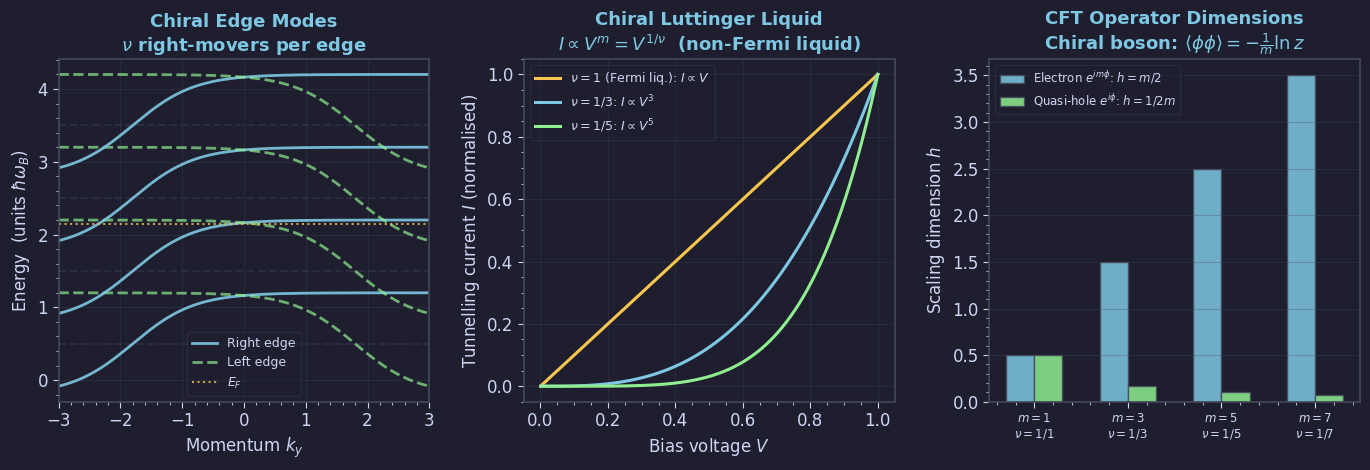

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'; TEAL='#4ecdc4'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
})

OUTDIR = 'figures/qhe'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

def text_panel(ax, title, items):
    ax.axis('off'); ax.set_title(title, color=BLUE)
    y=0.97
    for txt,col,fs in items:
        ax.text(0.03,y,txt,transform=ax.transAxes,color=col,fontsize=fs,va='top')
        y -= 0.09 if txt else 0.03

# ── Plot 6: Edge Modes & Bulk-Boundary Correspondence (Ch 6) ──────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Chiral edge mode dispersion in a QH bar
ax = axes[0]
k = np.linspace(-3, 3, 500)
for n in range(4):
    E0 = n + 0.5
    ax.axhline(E0, color=EDGE, lw=1.5, ls='--', alpha=0.35)
    # right edge: E increases with k (chiral right-mover)
    E_R = E0 + 0.7*np.tanh(k + 1.8)
    # left edge: E increases opposite (chiral left-mover, shown dashed)
    E_L = E0 + 0.7*np.tanh(-k + 1.8)
    ax.plot(k, E_R, color=BLUE,  lw=2.0, alpha=0.9, label='Right edge' if n==0 else None)
    ax.plot(k, E_L, color=GREEN, lw=2.0, alpha=0.7, ls='--',
            label='Left edge' if n==0 else None)
ax.axhline(2.15, color=YELLOW, lw=1.5, ls=':', alpha=0.8, label='$E_F$')
ax.set_xlabel('Momentum $k_y$')
ax.set_ylabel(r'Energy  (units $\hbar\omega_B$)')
ax.set_title('Chiral Edge Modes\n'+r'$\nu$ right-movers per edge', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True); ax.set_xlim(-3,3)

# Middle: Non-Fermi-liquid I-V at QH point contact
ax2 = axes[1]
V = np.linspace(0.001, 1.0, 400)
for m,col,lab in [(1, YELLOW, r'$\nu=1$ (Fermi liq.): $I\propto V$'),
                  (3, BLUE,   r'$\nu=1/3$: $I\propto V^3$'),
                  (5, GREEN,  r'$\nu=1/5$: $I\propto V^5$')]:
    I = V**m; I /= I[-1]  # Correct: I ~ V^(1/nu) = V^m (Kane-Fisher 1992)
    ax2.plot(V, I, color=col, lw=2.2, label=lab)
ax2.set_xlabel('Bias voltage $V$')
ax2.set_ylabel('Tunnelling current $I$ (normalised)')
ax2.set_title('Chiral Luttinger Liquid\n'+r'$I\propto V^m = V^{1/\nu}$  (non-Fermi liquid)', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)

# Right: CFT operator dimensions h_e = m/2, h_qh = 1/(2m)
ax3 = axes[2]
m_v = np.arange(1,8,2)
h_e  = m_v/2.0
h_qh = 1.0/(2*m_v)
x = np.arange(len(m_v)); w=0.3
ax3.bar(x-w/2, h_e,  width=w, color=BLUE,  alpha=0.85, edgecolor=EDGE,
        label=r'Electron $e^{im\phi}$: $h=m/2$')
ax3.bar(x+w/2, h_qh, width=w, color=GREEN, alpha=0.85, edgecolor=EDGE,
        label=r'Quasi-hole $e^{i\phi}$: $h=1/2m$')
ax3.set_xticks(x)
ax3.set_xticklabels([f'$m={m}$\n$\\nu=1/{m}$' for m in m_v], fontsize=8.5)
ax3.set_ylabel('Scaling dimension $h$')
ax3.set_title('CFT Operator Dimensions\n'+
              r'Chiral boson: $\langle\phi\phi\rangle=-\frac{1}{m}\ln z$', color=BLUE)
ax3.legend(fontsize=8.5, labelcolor=FG); ax3.grid(True, axis='y')

plt.tight_layout(pad=1.5)
save('plot6_edge_cft.png', fig)


---
## Plot 7 · Hofstadter Butterfly (Ch 2)

**Left**: Full Hofstadter butterfly — fractal energy spectrum for rational flux $\alpha=p/q$ up to $q=35$  
**Right**: Gap Chern numbers (TKNN) for $q=3,4,5$: $\sigma_{xy}=t\cdot e^2/h$ when $E_F$ in gap $r$ (corrected via Diophantine eq.)

  saved -> figures/qhe/plot7_hofstadter.png


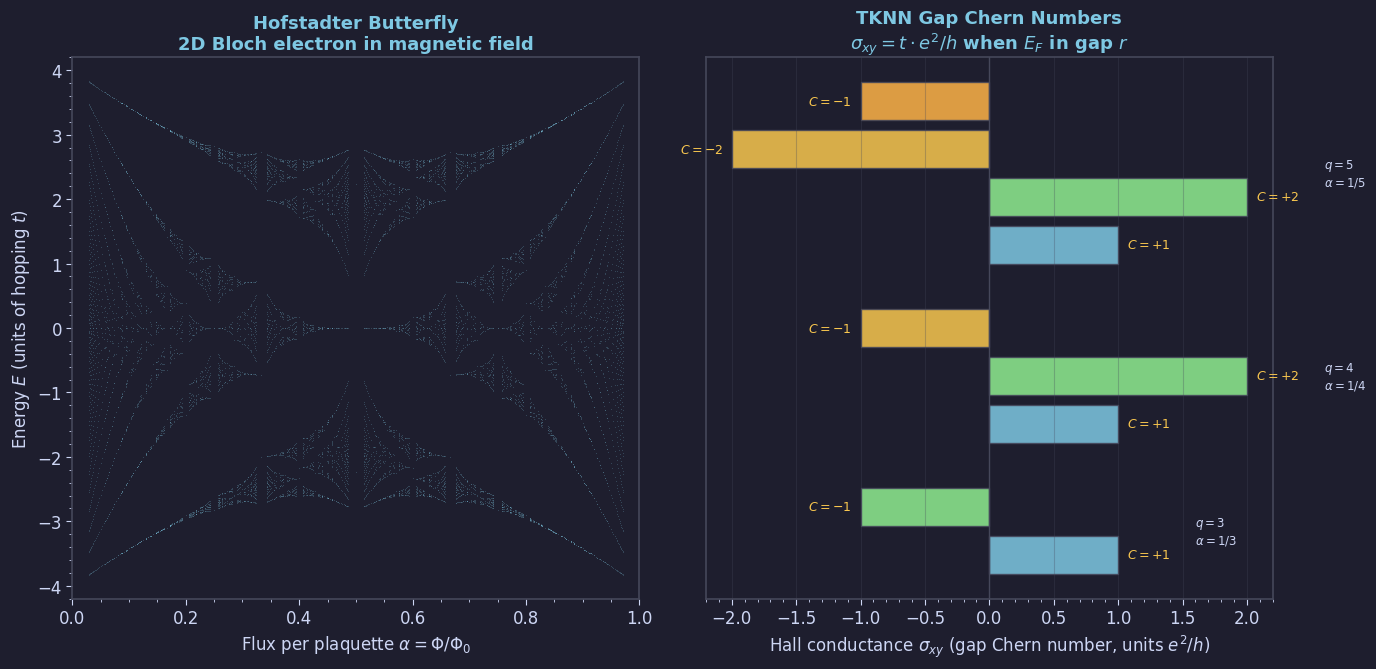

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'; TEAL='#4ecdc4'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
})

OUTDIR = 'figures/qhe'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

def text_panel(ax, title, items):
    ax.axis('off'); ax.set_title(title, color=BLUE)
    y=0.97
    for txt,col,fs in items:
        ax.text(0.03,y,txt,transform=ax.transAxes,color=col,fontsize=fs,va='top')
        y -= 0.09 if txt else 0.03

# ── Plot 7: Hofstadter Butterfly (Ch 2) ───────────────────────────────────
import math

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
fig.patch.set_facecolor(BG)

# Left: Hofstadter butterfly — Harper matrix eigenvalues at alpha = p/q
ax = axes[0]
pts_a, pts_E = [], []
for q in range(1, 36):
    for p in range(1, q):
        if math.gcd(p, q) != 1:
            continue
        alpha = p / q
        H = np.zeros((q, q))
        for i in range(q):
            H[i, i]           = 2.0 * np.cos(2*np.pi*alpha*i)
            H[i, (i+1) % q]   = 1.0
            H[(i+1) % q, i]   = 1.0
        eigs = np.linalg.eigvalsh(H)
        pts_a.extend([alpha]*q)
        pts_E.extend(eigs.tolist())

ax.scatter(pts_a, pts_E, s=0.15, color=BLUE, alpha=0.55, linewidths=0)
ax.set_xlabel(r'Flux per plaquette $\alpha=\Phi/\Phi_0$')
ax.set_ylabel(r'Energy $E$ (units of hopping $t$)')
ax.set_title('Hofstadter Butterfly\n2D Bloch electron in magnetic field', color=BLUE)
ax.set_xlim(0,1); ax.set_ylim(-4.2, 4.2); ax.grid(False)

# Right: Sub-band Chern numbers for q = 3, 4, 5
# (from TKNN Diophantine equation: t satisfying n = s + t*q, |t| <= q/2)
ax2 = axes[1]
# TKNN Diophantine: for alpha=1/q, gap r has sigma_xy = t*e^2/h
# where t satisfies r = t (mod q), |t| <= q/2
chern_data = {
    3: [ 1, -1],      # q=3 gaps: sigma=1,2 -> individual C: 1,-2 (cumulative shown)
    4: [ 1,  2, -1],  # q=4: sigma=1,2,-1
    5: [ 1,  2, -2, -1],  # q=5: sigma=1,2,-2,-1
}
cols5 = [BLUE, GREEN, YELLOW, ORANGE, PURPLE]
yoff = 0.0
for q, cherns in chern_data.items():
    for i, c in enumerate(cherns):
        ax2.barh(yoff + i*0.75, c, left=0, height=0.6,
                 color=cols5[i % len(cols5)], alpha=0.85, edgecolor=EDGE)
        ha = 'left' if c > 0 else 'right'
        ax2.text(c + (0.07 if c>0 else -0.07), yoff+i*0.75,
                 f'$C={c:+d}$', va='center', ha=ha, color=YELLOW, fontsize=9)
    mid = yoff + (len(cherns)-1)*0.75/2
    ax2.text(max(cherns)+0.6, mid,
             f'$q={q}$\n$\\alpha=1/{q}$', color=FG, fontsize=8.5, va='center')
    yoff += len(cherns)*0.75 + 0.55

ax2.axvline(0, color=EDGE, lw=1)
ax2.set_xlabel(r'Hall conductance $\sigma_{xy}$ (gap Chern number, units $e^2/h$)')
ax2.set_yticks([]); ax2.grid(True, axis='x')
ax2.set_title('TKNN Gap Chern Numbers\n'+r'$\sigma_{xy}=t\cdot e^2/h$ when $E_F$ in gap $r$', color=BLUE)

plt.tight_layout(pad=1.5)
save('plot7_hofstadter.png', fig)


---
## Download All Figures
Creates `qhe_figures.zip` containing all 7 plots and triggers download.

In [8]:
import os, zipfile
from google.colab import files

zip_path = 'qhe_figures.zip'
with zipfile.ZipFile(zip_path, 'w') as zf:
    for fname in sorted(os.listdir('figures/qhe')):
        fpath = os.path.join('figures/qhe', fname)
        zf.write(fpath, fname)
        print(f'  added {fname}')
print(f'\nZip created: {zip_path}')
files.download(zip_path)


  added plot1_classical_landau.png
  added plot2_berry_iqhe.png
  added plot3_laughlin_fqhe.png
  added plot4_nonabelian_anyons.png
  added plot5_chern_simons.png
  added plot6_edge_cft.png
  added plot7_hofstadter.png

Zip created: qhe_figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>